In [23]:
# 1. picture 폴더 안의 kite.jpg 활용하여 사진의 결과물을 만들기
# 2. 1의 결과물을 'kite_result.jpg' 라는 이름으로 이미지 저장하기
#   (cv2.imwrite(), np.concatenate() 추가로 알아보고 문제 풀기)

In [24]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')
%cd /content/drive/MyDrive/Colab_AI 영상처리

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
/content/drive/MyDrive/Colab_AI 영상처리


In [25]:
Image_Path = Path('picture/kite.jpg')
assert Image_Path.exists(), '이미지 파일이 없습니다.'

In [26]:
# 1. 이미지 읽어들이기
image = cv2.imread(str(Image_Path))
if image is None:
  raise FileNotFoundError('이미지를 읽지 못했습니다.')

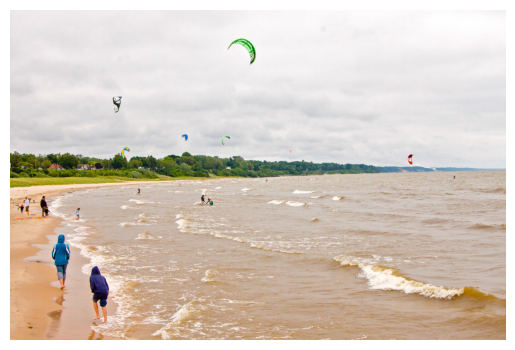

In [27]:
# 2. 원본 이미지 준비
image_rgb = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2RGB       # BGR to RGB
)

plt.imshow(image_rgb)
plt.axis('off')
plt.show()

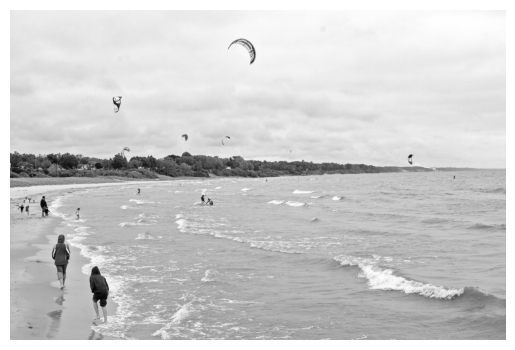

In [28]:
# 3. 흑백 이미지 준비
image_gray = cv2.cvtColor(
    image,
    cv2.COLOR_BGR2GRAY      # BGR -> GRAY(흑백)
)

plt.imshow(image_gray, cmap='gray')
plt.axis('off')
plt.show()

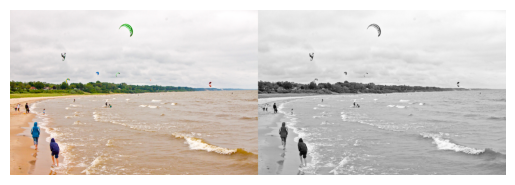

In [38]:
# 4. 원본+흑백 연결
#    rgb이미지(3차원 배열) + gray이미지(2차원 배열)

# 컬러->흑백 (빨강, 파랑, 초록 채널 개념 없애기)
# 흑백->컬러 (흑백을 유지하면서, (의미없는) 3차원 배열 변경)
image_gray2 = cv2.cvtColor(
    image_gray,
    cv2.COLOR_GRAY2RGB    # 표면적으로는 컬러로 바꿈, 실질적으로는 배열의 차원만 바꾸어줌
)

result = np.concatenate((image_rgb, image_gray2), axis=1)
# axis=0 (열 방향 연결, 기본값), axis=1 (행 방향 연결)

plt.imshow(result)
plt.axis('off')
plt.show()

In [44]:
# 5. 결과물 이미지(result) 저장
save_result = cv2.cvtColor(
    result,
    cv2.COLOR_RGB2BGR
)

cv2.imwrite('kite_result.jpg', save_result)    # BGR 방식

True